# eBPF Bottleneck Classifier v7_2 — Binary High-Severity Detection, Test-First Diagnostics

**Built on the v6 champion:** SMOTE + Random Forest, 3-class (Normal/Medium/High), Macro F1 = 0.690, Accuracy = 0.856.
The v6 confusion matrix showed the errors are *not* evenly spread — Medium↔Normal confusion (9,221 + 6,595 rows)
dwarfs Medium↔High confusion (966 + 358 rows), and Medium recall (0.380) is the weak link. High itself is already
reasonably separated (recall 0.763, precision 0.69).

Since the stated goal is **accurately detecting the High severity class** specifically, v7 reframes the problem as
**binary: High vs. not-High**, and spends its effort on the levers that the v6 confusion matrix says actually matter
for that goal — threshold calibration, decision-threshold tuning on `predict_proba`, and a robustness check —
rather than a generic re-run of the same pipeline.

| Section | Addresses |
|---|---|
| 1 | Rebuild the leakage-free feature set (carried over from v6, unchanged) |
| **TEST 1** | **Threshold calibration grid** — percentile ladder + candidate `HIGH_THRESHOLD_NS` grid, eyeball before hardcoding |
| 2 | Binary label derivation (High vs. not-High) using the calibrated threshold |
| **TEST 2** | **Binary vs. 3-class check** — does binary framing beat v6's isolated High precision/recall? |
| **TEST 3** | **Decision-threshold sweep** — precision/recall trade-off on `predict_proba`, before picking a deployment cutoff |
| **TEST 4** | **Boundary-zone feature audit** — do near-boundary "not-High" rows actually look like High on `cpu_migrations` / `runtime_per_switch`? |
| 3 | Stratified train/test split (frozen) |
| 4 | Class imbalance: baseline vs `class_weight` vs SMOTE vs Borderline-SMOTE vs ADASYN (binary) |
| 5 | Stratified k-fold CV robustness check on the champion (single-split can be split-lucky) |
| 6 | Light hyperparameter search (only after imbalance/threshold fixes) |
| 7-9 | Use the previous run?s selected champion; do not rerun candidate models for SHAP refinement |
| 10 | Inner-validation SHAP selection, champion-only retraining, threshold calibration, and final evaluation |

**Already completed the previous model run?** Do not use Run All for SHAP refinement. Keep the previous notebook kernel alive and run only the Section 10 cells; the earlier comparison/training cells are retained for reference and already provide `overall_champion` plus the prepared train/test data.

**Rules carried over from v6:**
- Resampling and scaling are fit **only** on `X_train`/`y_train`, never on the test set.
- The SHAP refinement starts from the previously selected champion. Feature selection and threshold calibration use an inner validation split; the final reduced champion is retrained on all training rows and evaluated on the held-out test set.
- Evaluation reports **High-class precision/recall/F1** and **PR-AUC**, not just accuracy — accuracy on an
  imbalanced binary problem is close to meaningless here (predicting "not-High" for everything gets ~95%+).

**Note on scope vs. v6:** v6's `MLPClassifier` comparison is dropped in v7 — it wasn't part of the specific
improvements this notebook targets, and tree ensembles were already the stronger, scale-invariant performer in v6.
If you want it back, Section 4's champion selection is a drop-in point.

**A note on execution:** The newly added SHAP selection/retraining and downstream evaluation cells have not been run here; run Section 10 in the previous run?s live kernel to refresh their outputs.

---
# Section 1 — Load & Rebuild the Leakage-Free Feature Set

Unchanged from v6. If you already have `df` with `FEATURE_COLS` in memory, you can skip to **TEST CELL 1**.

In [15]:
import warnings
warnings.filterwarnings('ignore')

import os
import gc
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_fscore_support, f1_score, accuracy_score,
    precision_recall_curve, average_precision_score, roc_auc_score, make_scorer
)

pd.set_option('display.float_format', '{:.3f}'.format)
pd.set_option('display.max_columns', 60)
sns.set_style('whitegrid')

RANDOM_STATE = 42

In [16]:
# -- Load multiple CSV parts (manually named, no auto-discovery) --------------
CSV_PARTS = [
    'perf_metrics1.csv',
    'perf_metrics2.csv',
    # add more here as you collect them
]
# -------------------------------------------------------------------------------

dfs = []
for path in CSV_PARTS:
    if not os.path.exists(path):
        print(f"  skipping (not found): {path}")
        continue
    part = pd.read_csv(path)
    part['source_file'] = path
    dfs.append(part)
    print(f"  loaded {path:<20}: {len(part):>8} rows")

df_raw = pd.concat(dfs, ignore_index=True)
print(f"\nCombined shape: {df_raw.shape}")
print(f"Sessions found : {df_raw['session_label'].unique().tolist()}")
df_raw['session_label'].value_counts()

  loaded perf_metrics1.csv   :   526895 rows
  loaded perf_metrics2.csv   :   250683 rows

Combined shape: (777578, 45)
Sessions found : ['idle', 'cpu_low', 'cpu_medium', 'cpu_high', 'cpu_overloaded', 'mem_low', 'mem_high', 'io_low', 'lock_low', 'mixed_load', 'cpu_extreme', 'cpu_ultra', 'mem_extreme', 'mem_thrashing', 'cpu_mem_extreme', 'cpu_mem_ultra', 'io_extreme', 'cpu_io_extreme', 'lock_extreme', 'lock_cpu_mix', 'everything_max', 'everything_insane', 'cpu_2x', 'cpu_4x', 'cpu_8x', 'mem_reclaim', 'mem_heavy_reclaim', 'cpu_mem_2x', 'cpu_mem_4x', 'cpu_mem_8x', 'cpu_mem_io', 'cpu_mem_io_heavy', 'lock_heavy', 'lock_cpu_heavy', 'everything_extreme', 'compile_only', 'compile_sysbench', 'compile_blender', 'full_system', 'mem_swap_thrashing', 'cpu_l3_cache_misses', 'mem_swap_thrash', 'mem_tlb_cache_miss', 'io_async_saturation', 'ctx_flood', 'llm_inference', 'ml_training', 'stream_memory_contention', 'cache_contention', 'context_switch_contention']


session_label
stream_memory_contention     146855
cache_contention             133428
context_switch_contention    121529
llm_inference                 39621
everything_max                21993
ml_training                   21422
everything_insane             20568
lock_cpu_heavy                11752
cpu_8x                        10213
lock_low                      10112
lock_heavy                     9933
everything_extreme             9705
cpu_mem_io                     9449
cpu_medium                     9261
full_system                    8964
cpu_low                        8331
cpu_mem_io_heavy               8082
cpu_mem_4x                     8024
cpu_mem_8x                     7969
mem_low                        7914
mem_extreme                    7764
mem_reclaim                    7449
compile_only                   6823
cpu_mem_2x                     6718
io_low                         6653
compile_sysbench               6585
compile_blender                6570
mem_tlb_cache_

In [17]:
# -- CLEANING (same rules as v6) -----------------------------------------------
df = df_raw.copy()
before = len(df)

df = df[df['pid'] > 0]
df = df[df['ctx_switches'] > 0]
df = df[df['latency_count'] > 0]

print(f"Cleaned: {before} -> {len(df)} rows ({before - len(df)} removed)")

Cleaned: 777578 -> 664256 rows (113322 removed)


In [18]:
# -- FEATURE ENGINEERING (causal signals only -- same as v6) ------------------
df['involuntary_ratio']  = df['involuntary_switches'] / df['ctx_switches'].clip(lower=1)
df['voluntary_ratio']    = df['voluntary_switches']   / df['ctx_switches'].clip(lower=1)
df['runtime_per_switch'] = df['total_runtime_ns']     / df['ctx_switches'].clip(lower=1)
df['read_write_ratio']   = df['read_bytes'] / (df['write_bytes'] + 1)
df['io_bytes_total']     = df['read_bytes'] + df['write_bytes']
df['alloc_pressure']     = df['total_alloc_bytes'] / df['ctx_switches'].clip(lower=1)
df['lock_pressure']      = (
    df['mutex_contentions'] + df['rwsem_read_contentions'] + df['rwsem_write_contentions']
)

log_cols = ['total_runtime_ns', 'avg_syscall_latency_ns', 'max_syscall_latency_ns',
            'io_bytes_total', 'total_alloc_bytes']
for col in log_cols:
    if col in df.columns:
        df[f'log_{col}'] = np.log1p(df[col])

print(f"Features after engineering: {df.shape[1]} columns")

Features after engineering: 57 columns


In [19]:
# -- EXPLICIT ALLOWLIST (no data leakage) -- identical to v6 ------------------
LEAKY_COLS = {
    'avg_stall_ns', 'stall_ns', 'max_stall_ns', 'latency_count',
    'stall_per_switch', 'log_stall_ns', 'log_avg_stall_ns', 'log_max_stall_ns',
    'stall_spike', 'log_stall_spike',
}

ALLOWED_FEATURES = [
    'ctx_switches', 'cpu_migrations', 'involuntary_switches', 'voluntary_switches',
    'involuntary_ratio', 'voluntary_ratio', 'avg_runq_ratio', 'runtime_per_switch',
    'minor_faults', 'major_faults', 'kmalloc_count', 'kfree_count',
    'total_alloc_bytes', 'alloc_pressure',
    'read_count', 'write_count', 'read_bytes', 'write_bytes', 'read_write_ratio', 'io_bytes_total',
    'mutex_contentions', 'avg_mutex_wait_ns', 'rwsem_read_contentions', 'rwsem_write_contentions', 'lock_pressure',
    'syscall_count', 'avg_syscall_latency_ns', 'futex_count',
    'log_total_runtime_ns', 'log_avg_syscall_latency_ns', 'log_max_syscall_latency_ns',
    'log_io_bytes_total', 'log_total_alloc_bytes',
]

FEATURE_COLS = [f for f in ALLOWED_FEATURES if f in df.columns]

leakage_check = set(FEATURE_COLS) & LEAKY_COLS
assert len(leakage_check) == 0, f"LEAKAGE DETECTED: {leakage_check}"
print(f"Leakage check passed -- {len(FEATURE_COLS)} features, none target-derived")

Leakage check passed -- 33 features, none target-derived


---
## TEST CELL 1 — Threshold Calibration Grid  *(eyeball before proceeding)*

v6's markdown promised this grid and then hardcoded `NORMAL_THRESHOLD_NS=500k` / `HIGH_THRESHOLD_NS=1.5M` without
ever printing it. Building it now: the real percentile ladder for `avg_stall_ns`, plus the resulting % of rows
flagged High at a range of candidate cutoffs. Look for an inflection point (a percentile band where values jump)
rather than picking a round number blind. If the grid shows the ~1.5ms cutoff lands in a near-empty or wildly
imbalanced spot, adjust `HIGH_THRESHOLD_NS` in the next cell before moving on.

In [20]:
# -- Percentile ladder (informational -- not the label itself) ----------------
percentiles = [50, 75, 85, 90, 95, 97, 98, 99, 99.5, 99.9]
ladder_ms = (df['avg_stall_ns'].quantile([p / 100 for p in percentiles]) / 1e6).round(3)
ladder_ms.index = [f'p{p}' for p in percentiles]
print("avg_stall_ns percentile ladder (ms):")
print(ladder_ms.to_string())

# -- Candidate HIGH_THRESHOLD_NS grid ------------------------------------------
candidate_high_thresholds_ns = [500_000, 750_000, 1_000_000, 1_250_000,
                                 1_500_000, 2_000_000, 3_000_000, 5_000_000]

print("\nCandidate High cutoffs vs. resulting class balance:")
print(f"{'threshold_ns':>14}  {'threshold_ms':>12}  {'%% flagged High':>16}  {'row count':>10}")
for t in candidate_high_thresholds_ns:
    flagged = df['avg_stall_ns'] >= t
    print(f"{t:>14,}  {t/1e6:>12.2f}  {100*flagged.mean():>15.2f}%  {flagged.sum():>10,}")

print("\nv6 used 1,500,000 ns (1.5ms) as HIGH_THRESHOLD_NS. Confirm above that this lands on a reasonable")
print("inflection point and not a near-empty tail before reusing it below.")

avg_stall_ns percentile ladder (ms):
p50      0.160
p75      0.412
p85      0.524
p90      0.650
p95      1.189
p97      2.738
p98      4.065
p99      5.797
p99.5    7.312
p99.9   14.845

Candidate High cutoffs vs. resulting class balance:
  threshold_ns  threshold_ms   %% flagged High   row count
       500,000          0.50            16.71%     110,978
       750,000          0.75             8.25%      54,814
     1,000,000          1.00             5.60%      37,210
     1,250,000          1.25             4.85%      32,242
     1,500,000          1.50             4.34%      28,804
     2,000,000          2.00             3.66%      24,311
     3,000,000          3.00             2.75%      18,287
     5,000,000          5.00             1.35%       8,978

v6 used 1,500,000 ns (1.5ms) as HIGH_THRESHOLD_NS. Confirm above that this lands on a reasonable
inflection point and not a near-empty tail before reusing it below.


---
# Section 2 — Binary Label Derivation (High vs. Not-High)

`HIGH_THRESHOLD_NS` below should be set from the TEST CELL 1 grid above -- kept as a fixed, reproducible cutoff
(not a data-relative percentile, matching v6's reasoning for reproducibility across collection runs). Everything
below `HIGH_THRESHOLD_NS` (both the old Normal and Medium buckets) collapses into a single `Not-High` class,
since the goal is bottleneck *detection*, not fine-grained severity.

In [21]:
HIGH_THRESHOLD_NS = 1_500_000   # 1.5 ms -- set from the TEST CELL 1 grid above

df['y'] = (df['avg_stall_ns'] >= HIGH_THRESHOLD_NS).astype(int)
class_names_map = {0: 'Not-High', 1: 'High'}
TARGET_NAMES  = ['Not-High', 'High']
TARGET_LABELS = [0, 1]

print(f"Fixed threshold (ns): High >= {HIGH_THRESHOLD_NS:,}\n")
for cls in TARGET_LABELS:
    count = (df['y'] == cls).sum()
    pct = 100 * count / len(df)
    print(f"  Class {cls} ({class_names_map[cls]:<9}): {count:7d} rows  ({pct:5.1f}%)")

Fixed threshold (ns): High >= 1,500,000

  Class 0 (Not-High ):  635452 rows  ( 95.7%)
  Class 1 (High     ):   28804 rows  (  4.3%)


---
## TEST CELL 2 — Binary vs. 3-Class Check  *(eyeball before proceeding)*

Before adopting binary as the deployed framing, confirm it's actually competitive with v6's 3-class model's
**isolated High performance** -- not just "different," but as good or better on the metric that matters
(precision/recall on High). This trains one quick, unresampled-but-balanced RF purely for this comparison; it is
not the final model.

**Caveat on reading this cell's numbers:** this quick model uses `class_weight='balanced'` at the default 0.5 threshold, not SMOTE -- and v6's own comparison table already showed `class_weight='balanced'` trading precision for recall relative to SMOTE (macro F1 0.637 vs. 0.690). So a precision gap here against the SMOTE-based v6 reference is expected and is **not** a verdict on binary framing -- it's an imbalance-method mismatch. The real comparison happens in Section 4, once SMOTE/Borderline-SMOTE/ADASYN run on the binary target too.

In [22]:
# v6 champion (SMOTE, 3-class) -- isolated High-class numbers, for reference
V6_HIGH_PRECISION_REF = 0.69
V6_HIGH_RECALL_REF    = 0.763
V6_HIGH_F1_REF        = 0.73

X = df[FEATURE_COLS].fillna(0)
y_bin = df['y']

X_tr_q, X_te_q, y_tr_q, y_te_q = train_test_split(
    X, y_bin, test_size=0.2, stratify=y_bin, random_state=RANDOM_STATE
)

quick_rf = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=5, class_weight='balanced',
    n_jobs=4, random_state=RANDOM_STATE
)
quick_rf.fit(X_tr_q, y_tr_q)
quick_pred = quick_rf.predict(X_te_q)

prec, rec, f1, _ = precision_recall_fscore_support(
    y_te_q, quick_pred, labels=[1], zero_division=0
)
print("Quick binary check (class_weight='balanced', default 0.5 threshold, no resampling yet):")
print(f"  High precision : {prec[0]:.3f}   (v6 3-class isolated High: {V6_HIGH_PRECISION_REF:.3f})")
print(f"  High recall    : {rec[0]:.3f}   (v6 3-class isolated High: {V6_HIGH_RECALL_REF:.3f})")
print(f"  High F1        : {f1[0]:.3f}   (v6 3-class isolated High: {V6_HIGH_F1_REF:.3f})")
print("\nIf this is already close to or better than the v6 reference -- even before resampling, threshold")
print("tuning, or hyperparameter search -- binary framing is worth adopting as the primary track. If it's")
print("notably worse, that's a sign the Not-High bucket (Normal+Medium merged) is harder to separate from")
print("High than Medium alone was, and the parallel/3-class approach may be worth keeping instead.")

Quick binary check (class_weight='balanced', default 0.5 threshold, no resampling yet):
  High precision : 0.453   (v6 3-class isolated High: 0.690)
  High recall    : 0.875   (v6 3-class isolated High: 0.763)
  High F1        : 0.597   (v6 3-class isolated High: 0.730)

If this is already close to or better than the v6 reference -- even before resampling, threshold
tuning, or hyperparameter search -- binary framing is worth adopting as the primary track. If it's
notably worse, that's a sign the Not-High bucket (Normal+Medium merged) is harder to separate from
High than Medium alone was, and the parallel/3-class approach may be worth keeping instead.


---
## TEST CELL 3 — Decision-Threshold Sweep  *(eyeball before proceeding)*

Default classifiers cut at `P(High) >= 0.5`. Sweeping the threshold shows whether a different cutoff buys
meaningfully higher precision without cratering recall -- reusing `quick_rf` from TEST CELL 2 (not yet the
final tuned champion, just enough signal to know whether this lever is worth building into the pipeline).

PR-AUC (average precision) at this quick pass: 0.825

 threshold   precision    recall
     0.655       0.600     0.815
     0.731       0.700     0.776
     0.781       0.750     0.746
     0.841       0.800     0.698
     0.872       0.850     0.660
     0.923       0.900     0.606


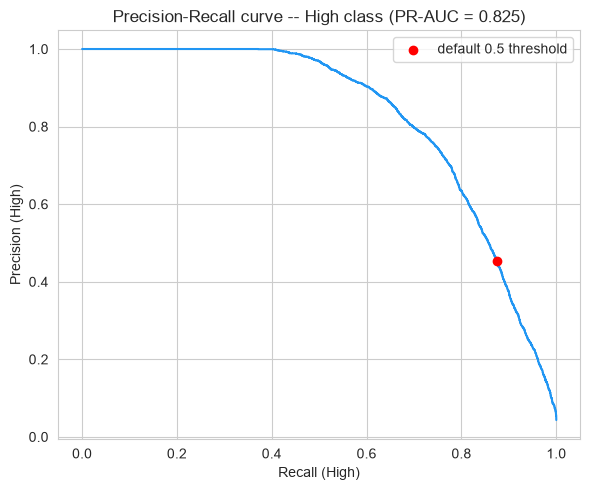


If the curve shows a threshold that meaningfully raises precision while recall stays usable,
carry that insight into Section 8's final threshold tuning below.


In [23]:
probs_q = quick_rf.predict_proba(X_te_q)[:, 1]
prec_arr, rec_arr, thresh_arr = precision_recall_curve(y_te_q, probs_q)
ap_q = average_precision_score(y_te_q, probs_q)

print(f"PR-AUC (average precision) at this quick pass: {ap_q:.3f}\n")
print(f"{'threshold':>10}  {'precision':>10}  {'recall':>8}")
for target_prec in [0.60, 0.70, 0.75, 0.80, 0.85, 0.90]:
    hits = np.where(prec_arr[:-1] >= target_prec)[0]
    if len(hits) == 0:
        print(f"{'--':>10}  {'n/a':>10}  precision {target_prec:.2f} not reachable at any threshold")
        continue
    idx = hits[0]
    print(f"{thresh_arr[idx]:>10.3f}  {prec_arr[idx]:>10.3f}  {rec_arr[idx]:>8.3f}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(rec_arr, prec_arr, color='#2196F3')
ax.scatter(rec[0], prec[0], color='red', zorder=5, label='default 0.5 threshold')
ax.set_xlabel('Recall (High)')
ax.set_ylabel('Precision (High)')
ax.set_title(f'Precision-Recall curve -- High class (PR-AUC = {ap_q:.3f})')
ax.legend()
plt.tight_layout()
plt.savefig('pr_curve_quick_check.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nIf the curve shows a threshold that meaningfully raises precision while recall stays usable,")
print("carry that insight into Section 8's final threshold tuning below.")

---
## TEST CELL 4 — Boundary-Zone Feature Audit  *(eyeball before proceeding)*

The old Medium class sat between 0.5ms and 1.5ms and was the weak point in v6 (recall 0.380, mostly confused
with Normal). Now that Medium is folded into Not-High, check whether that same near-boundary zone
(0.5ms <= avg_stall_ns < 1.5ms) still looks meaningfully different from High on the top features -- or whether
it looks closer to High than the clearly-normal rows do, which would explain any false positives/negatives
clustering near the boundary rather than a resampling or threshold problem.

In [24]:
boundary_zone   = df[(df['avg_stall_ns'] >= 500_000) & (df['avg_stall_ns'] < HIGH_THRESHOLD_NS)]
clearly_normal  = df[df['avg_stall_ns'] < 500_000]
high_rows       = df[df['y'] == 1]

audit_features = ['cpu_migrations', 'runtime_per_switch']

print(f"{'feature':<20} {'clearly_normal':>15} {'boundary_zone':>15} {'high':>12}   p(boundary~high)  p(normal~high)")
for feat in audit_features:
    med_cn = clearly_normal[feat].median()
    med_bz = boundary_zone[feat].median()
    med_hi = high_rows[feat].median()
    _, p_bz_hi = mannwhitneyu(boundary_zone[feat], high_rows[feat], alternative='two-sided')
    _, p_cn_hi = mannwhitneyu(clearly_normal[feat], high_rows[feat], alternative='two-sided')
    print(f"{feat:<20} {med_cn:>15.2f} {med_bz:>15.2f} {med_hi:>12.2f}   {p_bz_hi:>16.4g}  {p_cn_hi:>15.4g}")

print("\nIf boundary_zone's median sits meaningfully closer to high's than clearly_normal's does (and the")
print("Mann-Whitney p-value for boundary~high is much larger, i.e. less distinguishable, than normal~high),")
print("that overlap is a real signal-level limit -- not something more resampling or threshold tuning fixes.")
print("It points instead at needing a new discriminative feature, per v6's own 'next steps' note.")

feature               clearly_normal   boundary_zone         high   p(boundary~high)  p(normal~high)
cpu_migrations                  1.00            1.00       128.00                  0                0
runtime_per_switch          74321.22       102643.82   2354757.97                  0                0

If boundary_zone's median sits meaningfully closer to high's than clearly_normal's does (and the
Mann-Whitney p-value for boundary~high is much larger, i.e. less distinguishable, than normal~high),
that overlap is a real signal-level limit -- not something more resampling or threshold tuning fixes.
It points instead at needing a new discriminative feature, per v6's own 'next steps' note.


---
### STOP — review TEST CELLS 1-4 above before continuing

If the threshold grid looks sane, binary framing is competitive with (or better than) v6's isolated High
numbers, a usable precision/recall trade-off exists, and the boundary-zone audit doesn't reveal a hard
signal-level ceiling -- proceed to the pipeline below. Otherwise, adjust `HIGH_THRESHOLD_NS` above and re-run
from TEST CELL 1, or reconsider whether binary framing is the right call, before committing further compute.

In [25]:
del quick_rf, quick_pred, probs_q, prec_arr, rec_arr, thresh_arr
gc.collect()

3129

---
# Section 3 — Stratified Train/Test Split (Frozen)

Same discipline as v6: this split is frozen and never touched by resampling, scaling, or threshold tuning below.

In [26]:
X = df[FEATURE_COLS].fillna(0)
y = df['y']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
X_train = X_train.astype('float32')
X_test = X_test.astype('float32')

test_context = df.loc[X_test.index, ['comm', 'session_label', 'avg_stall_ns', 'max_stall_ns']]

print(f"Train: {len(X_train)} rows | Test: {len(X_test)} rows (frozen)\n")
print("Class distribution -- Train:")
print((y_train.value_counts(normalize=True).sort_index() * 100).round(1).to_string())
print("\nClass distribution -- Test:")
print((y_test.value_counts(normalize=True).sort_index() * 100).round(1).to_string())

Train: 531404 rows | Test: 132852 rows (frozen)

Class distribution -- Train:
y
0   95.700
1    4.300

Class distribution -- Test:
y
0   95.700
1    4.300


---
# Section 4 — Class Imbalance: Baseline vs `class_weight` vs SMOTE vs Borderline-SMOTE vs ADASYN

Same five strategies as v6, same fixed RF architecture, now scored on the binary High class specifically
(precision/recall/F1 for High, plus PR-AUC and ROC-AUC since we now have well-defined positive-class
probabilities to work with).

In [27]:
try:
    from imblearn.over_sampling import SMOTE, BorderlineSMOTE, ADASYN
    HAS_IMBLEARN = True
except ImportError:
    print("imbalanced-learn not installed. Run: pip install imbalanced-learn --break-system-packages")
    HAS_IMBLEARN = False

In [28]:
def evaluate_predictions(y_true, y_pred, y_proba, name):
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, sup = precision_recall_fscore_support(
        y_true, y_pred, labels=TARGET_LABELS, zero_division=0
    )
    macro_f1 = f1.mean()
    weighted_f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    result = {
        'strategy': name,
        'accuracy': acc,
        'macro_f1': macro_f1,
        'weighted_f1': weighted_f1,
        'precision_high': prec[1],
        'recall_high': rec[1],
        'f1_high': f1[1],
    }
    if y_proba is not None:
        result['pr_auc_high'] = average_precision_score(y_true, y_proba)
        result['roc_auc_high'] = roc_auc_score(y_true, y_proba)
    return result

imbalance_results = []
imbalance_models = {}
confusion_matrices = {}

# 1. Baseline -- no resampling, no class weighting
rf_baseline = RandomForestClassifier(
    n_estimators=300, min_samples_leaf=5, class_weight=None,
    n_jobs=4, random_state=RANDOM_STATE
)
rf_baseline.fit(X_train, y_train)
pred = rf_baseline.predict(X_test)
proba = rf_baseline.predict_proba(X_test)[:, 1]
imbalance_results.append(evaluate_predictions(y_test, pred, proba, 'Baseline (no handling)'))
confusion_matrices['Baseline (no handling)'] = confusion_matrix(y_test, pred, labels=TARGET_LABELS)
imbalance_models['Baseline (no handling)'] = rf_baseline
del rf_baseline, pred, proba; gc.collect()

# 2. class_weight='balanced'
rf_balanced = RandomForestClassifier(
    n_estimators=300, min_samples_leaf=5, class_weight='balanced',
    n_jobs=4, random_state=RANDOM_STATE
)
rf_balanced.fit(X_train, y_train)
pred = rf_balanced.predict(X_test)
proba = rf_balanced.predict_proba(X_test)[:, 1]
imbalance_results.append(evaluate_predictions(y_test, pred, proba, "class_weight=balanced"))
confusion_matrices["class_weight=balanced"] = confusion_matrix(y_test, pred, labels=TARGET_LABELS)
imbalance_models["class_weight=balanced"] = rf_balanced
del rf_balanced, pred, proba; gc.collect()

resamplers = {}
if HAS_IMBLEARN:
    resamplers = {
        'SMOTE': SMOTE(random_state=RANDOM_STATE),
        'Borderline-SMOTE': BorderlineSMOTE(random_state=RANDOM_STATE),
        'ADASYN': ADASYN(random_state=RANDOM_STATE),
    }
    for name, resampler in resamplers.items():
        X_res, y_res = resampler.fit_resample(X_train, y_train)
        rf_res = RandomForestClassifier(
            n_estimators=300, min_samples_leaf=5, class_weight=None,
            n_jobs=4, random_state=RANDOM_STATE
        )
        rf_res.fit(X_res, y_res)
        pred = rf_res.predict(X_test)
        proba = rf_res.predict_proba(X_test)[:, 1]
        imbalance_results.append(evaluate_predictions(y_test, pred, proba, name))
        confusion_matrices[name] = confusion_matrix(y_test, pred, labels=TARGET_LABELS)
        imbalance_models[name] = rf_res
        del X_res, y_res, rf_res, pred, proba; gc.collect()
else:
    print("Skipped resampling strategies -- imbalanced-learn not installed.")

imbalance_df = pd.DataFrame(imbalance_results).set_index('strategy')
imbalance_df.round(3)

,accuracy,macro_f1,weighted_f1,precision_high,recall_high,f1_high,pr_auc_high,roc_auc_high
strategy,,,,,,,,
Baseline (no handling),0.981,0.865,0.979,0.888,0.634,0.740,0.830,0.974
class_weight=balanced,0.949,0.784,0.956,0.452,0.875,0.596,0.825,0.975
SMOTE,0.975,0.856,0.975,0.683,0.771,0.724,0.817,0.972
Borderline-SMOTE,0.974,0.854,0.975,0.675,0.773,0.721,0.815,0.971
ADASYN,0.970,0.840,0.972,0.621,0.789,0.695,0.810,0.971


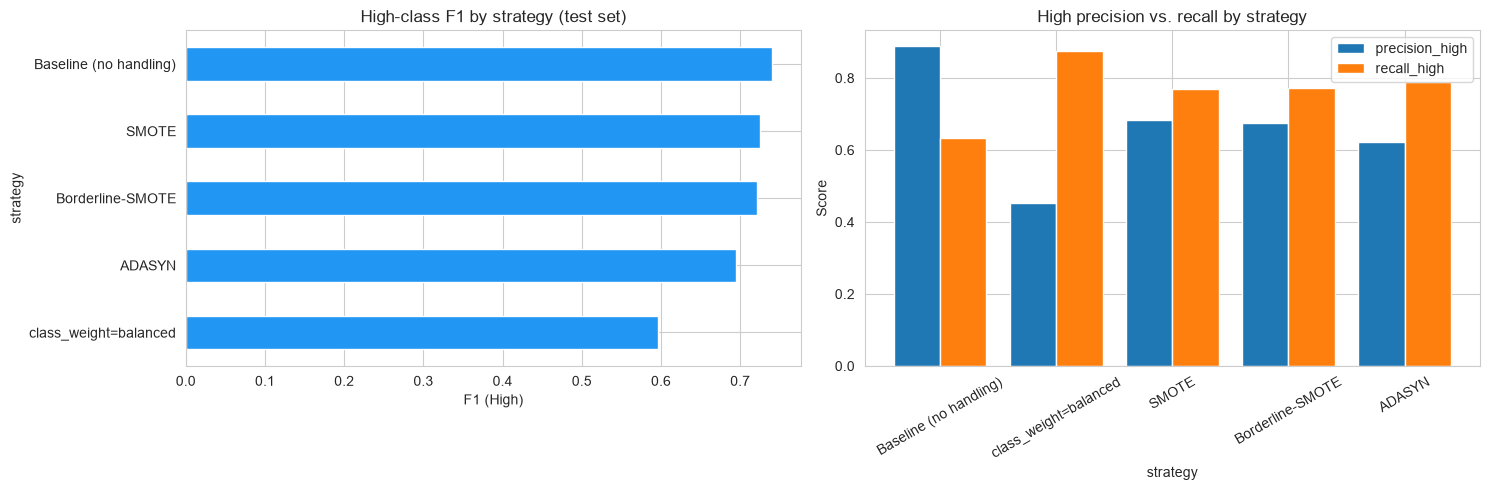


Best strategy by High-class F1: 'Baseline (no handling)' (F1=0.740, precision=0.888, recall=0.634)


In [29]:
# -- Visual comparison ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

imbalance_df['f1_high'].sort_values().plot(kind='barh', ax=axes[0], color='#2196F3', edgecolor='white')
axes[0].set_title('High-class F1 by strategy (test set)')
axes[0].set_xlabel('F1 (High)')

imbalance_df[['precision_high', 'recall_high']].plot(kind='bar', ax=axes[1], width=0.8)
axes[1].set_title('High precision vs. recall by strategy')
axes[1].set_ylabel('Score')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('imbalance_strategy_comparison_v7.png', dpi=150, bbox_inches='tight')
plt.show()

best_strategy = imbalance_df['f1_high'].idxmax()
print(f"\nBest strategy by High-class F1: '{best_strategy}' (F1={imbalance_df.loc[best_strategy, 'f1_high']:.3f}, "
      f"precision={imbalance_df.loc[best_strategy, 'precision_high']:.3f}, "
      f"recall={imbalance_df.loc[best_strategy, 'recall_high']:.3f})")

---
# Section 5 — Stratified K-Fold CV Robustness Check

v6 evaluated everything on a single 80/20 split. Before the best strategy above goes into the champion artifact,
confirm its High-class F1 isn't just a lucky split: run 5-fold stratified CV with the resampler correctly
scoped inside each fold (via an imblearn `Pipeline`, so synthetic points never leak across the fold boundary).

In [30]:
from imblearn.pipeline import Pipeline as ImbPipeline

f1_high_scorer = make_scorer(f1_score, pos_label=1, zero_division=0)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

if HAS_IMBLEARN and best_strategy in resamplers:
    cv_pipeline = ImbPipeline([
        ('resample', resamplers[best_strategy]),
        ('clf', RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight=None,
                                        n_jobs=4, random_state=RANDOM_STATE)),
    ])
else:
    class_weight = 'balanced' if best_strategy == 'class_weight=balanced' else None
    cv_pipeline = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight=class_weight,
                                          n_jobs=4, random_state=RANDOM_STATE)

cv_scores = cross_val_score(cv_pipeline, X_train, y_train, cv=skf, scoring=f1_high_scorer, n_jobs=1)

print(f"5-fold CV High-class F1 for '{best_strategy}': {cv_scores.round(3).tolist()}")
print(f"  mean = {cv_scores.mean():.3f}   std = {cv_scores.std():.3f}")
print(f"  single-split High F1 was {imbalance_df.loc[best_strategy, 'f1_high']:.3f}")
print("\nIf the single-split number falls within roughly one std of the CV mean, it's not split-lucky and")
print("it's safe to proceed with hyperparameter search below. A big gap means re-check the split or investigate")
print("session_label leakage between train/test (e.g. the same process instance split across both).")

5-fold CV High-class F1 for 'Baseline (no handling)': [0.742, 0.736, 0.731, 0.724, 0.732]
  mean = 0.733   std = 0.006
  single-split High F1 was 0.740

If the single-split number falls within roughly one std of the CV mean, it's not split-lucky and
it's safe to proceed with hyperparameter search below. A big gap means re-check the split or investigate
session_label leakage between train/test (e.g. the same process instance split across both).


---
# Section 6 — Light Hyperparameter Search

Only now, after imbalance handling and the threshold lever have already been checked (Sections 4-5, TEST 3) --
tuning a reasonable RF further is a smaller lever than those and not worth spending compute on first.
Small grid, scored on High-class F1, reusing the winning resampling strategy.

In [ ]:
# param_grid = {
#     'n_estimators': [200, 300, 500],
#     'max_depth': [None, 12, 20],
#     'min_samples_leaf': [1, 5, 10],
# }

# if HAS_IMBLEARN and best_strategy in resamplers:
#     X_train_search, y_train_search = resamplers[best_strategy].fit_resample(X_train, y_train)
#     class_weight = None
# else:
#     X_train_search, y_train_search = X_train, y_train
#     class_weight = 'balanced' if best_strategy == 'class_weight=balanced' else None

# base_rf = RandomForestClassifier(class_weight=class_weight, n_jobs=4, random_state=RANDOM_STATE)
# grid_search = GridSearchCV(
#     base_rf, param_grid, scoring=f1_high_scorer, cv=3, n_jobs=1, refit=True
# )
# grid_search.fit(X_train_search, y_train_search)

# print(f"Best params: {grid_search.best_params_}")
# print(f"Best CV High-class F1: {grid_search.best_score_:.3f}")

# tuned_model = grid_search.best_estimator_
# tuned_pred = tuned_model.predict(X_test)
# tuned_proba = tuned_model.predict_proba(X_test)[:, 1]
# tuned_result = evaluate_predictions(y_test, tuned_pred, tuned_proba, f'Tuned ({best_strategy})')
# print(f"\nTuned model on frozen test set: precision={tuned_result['precision_high']:.3f}, "
#       f"recall={tuned_result['recall_high']:.3f}, F1={tuned_result['f1_high']:.3f}")

# del X_train_search, y_train_search, tuned_pred; gc.collect()

KeyboardInterrupt: 

In [32]:
tuned_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=20,
    min_samples_leaf=1,
    class_weight=class_weight,
    n_jobs=4,
    random_state=RANDOM_STATE,
)

tuned_model.fit(X_train_search, y_train_search)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total nu

---
# Sections 7-9 ? Previous Run Champion

These cells are intentionally skipped: the previous run already selected and fitted the champion. Run Section 10 directly in that same kernel; it uses the existing champion and train/test data without rerunning candidate models.

---
# Section 10 ? SHAP Refinement of the Previous Champion

Run only these Section 10 cells after the previous run has populated `overall_champion`, `overall_champion_name`, X_train, y_train, X_test, and y_test. This does not refit the candidate models, rerun the search, or change which model family won.

The workflow uses an inner split of the original training data: fit the selected champion configuration on the inner-train partition, compute positive-class SHAP importance there, keep the smallest ranked feature set covering 95% of cumulative importance, and choose a probability threshold on the inner validation partition. Then refit only the reduced-feature champion on all original training rows and evaluate it once on the existing test split.

The test split is not used for SHAP ranking or threshold selection. However, if the prior run used this same test split to choose the champion, its results are no longer a pristine independent final test; use a new dataset or untouched holdout for an unbiased final performance claim.

In [33]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split

overall_champion = tuned_model  # Or your preferred model from imbalance_models
overall_champion_name = 'Tuned RF'

required_names = ['overall_champion', 'overall_champion_name', 'X_train', 'y_train', 'X_test', 'y_test']
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError(
        f"Previous-run state is missing {missing_names}. Load the prior champion and prepared train/test data first; "
        "do not rerun model comparisons just for SHAP."
    )
PREVIOUS_CHAMPION_NAME = str(overall_champion_name)
if not isinstance(overall_champion, RandomForestClassifier):
    raise TypeError(
        f"Expected the selected champion to be RandomForestClassifier, got {type(overall_champion).__name__}. "
        "This SHAP workflow is written for the Random Forest champion."
    )
if list(X_train.columns) != list(FEATURE_COLS):
    raise ValueError("X_train columns do not match FEATURE_COLS; verify that the previous-run data preparation is loaded.")

if str(overall_champion_name).startswith('Tuned'):
    champion_strategy = best_strategy
elif str(overall_champion_name) in imbalance_models:
    champion_strategy = overall_champion_name
else:
    raise ValueError(f"Cannot map champion '{overall_champion_name}' to its prior imbalance strategy.")
if champion_strategy not in {'Baseline (no handling)', 'class_weight=balanced'} and champion_strategy not in resamplers:
    raise ValueError(f"Champion strategy '{champion_strategy}' has no available training-only resampler.")

X_inner_train, X_inner_valid, y_inner_train, y_inner_valid = train_test_split(
    X_train, y_train, test_size=0.20, stratify=y_train, random_state=RANDOM_STATE
)

def fit_champion_for_split(X_fit, y_fit):
    if HAS_IMBLEARN and champion_strategy in resamplers:
        X_fit_resampled, y_fit_resampled = resamplers[champion_strategy].fit_resample(X_fit, y_fit)
    else:
        X_fit_resampled, y_fit_resampled = X_fit, y_fit
    model = clone(overall_champion)
    model.fit(X_fit_resampled, y_fit_resampled)
    return model

champion_inner_model = fit_champion_for_split(X_inner_train, y_inner_train)
try:
    import shap
except ImportError as e:
    raise ImportError("SHAP is required for this refinement. Install shap, then rerun Section 10.") from e

shap_sample = X_inner_train.sample(min(1000, len(X_inner_train)), random_state=RANDOM_STATE)
champion_explainer = shap.TreeExplainer(champion_inner_model)
champion_shap_values = champion_explainer.shap_values(shap_sample, check_additivity=False)
if isinstance(champion_shap_values, list):
    positive_class_shap = champion_shap_values[1]
else:
    champion_shap_values = np.asarray(champion_shap_values)
    positive_class_shap = champion_shap_values[:, :, 1] if champion_shap_values.ndim == 3 else champion_shap_values

shap_importance = pd.Series(
    np.abs(positive_class_shap).mean(axis=0), index=FEATURE_COLS
).sort_values(ascending=False)
SHAP_CUMULATIVE_IMPORTANCE = 0.95
importance_total = shap_importance.sum()
if not np.isfinite(importance_total) or importance_total <= 0:
    raise ValueError("Champion SHAP importances have no positive finite total; feature selection is not possible.")
feature_count = int(np.searchsorted(
    (shap_importance.cumsum() / importance_total).to_numpy(),
    SHAP_CUMULATIVE_IMPORTANCE,
    side='left',
) + 1)
SHAP_SELECTED_FEATURES = shap_importance.index[:feature_count].tolist()
print(f"Champion: {overall_champion_name}")
print(f"Selected {len(SHAP_SELECTED_FEATURES)} of {len(FEATURE_COLS)} features to cover {SHAP_CUMULATIVE_IMPORTANCE:.0%} cumulative positive-class SHAP importance:")
display(shap_importance.loc[SHAP_SELECTED_FEATURES].to_frame('mean_abs_shap'))

champion_inner_reduced = fit_champion_for_split(
    X_inner_train.loc[:, SHAP_SELECTED_FEATURES], y_inner_train
)
validation_probability = champion_inner_reduced.predict_proba(
    X_inner_valid.loc[:, SHAP_SELECTED_FEATURES]
)[:, 1]
valid_precision, valid_recall, valid_thresholds = precision_recall_curve(
    y_inner_valid, validation_probability
)
valid_f1 = np.divide(
    2 * valid_precision[:-1] * valid_recall[:-1],
    valid_precision[:-1] + valid_recall[:-1],
    out=np.zeros_like(valid_precision[:-1]),
    where=(valid_precision[:-1] + valid_recall[:-1]) > 0,
)
if not len(valid_thresholds):
    raise ValueError("Validation split produced no probability thresholds; cannot calibrate the decision cutoff.")
threshold_idx = int(np.argmax(valid_f1))
DECISION_THRESHOLD = float(valid_thresholds[threshold_idx])
print(f"Validation-selected decision threshold (max High-class F1): {DECISION_THRESHOLD:.4f}")
print(f"Inner validation High-class F1: {valid_f1[threshold_idx]:.4f}")

Champion: Tuned RF
Selected 20 of 33 features to cover 95% cumulative positive-class SHAP importance:


,mean_abs_shap
runtime_per_switch,0.021
cpu_migrations,0.016
involuntary_ratio,0.011
ctx_switches,0.010
voluntary_switches,0.010
voluntary_ratio,0.009
log_total_runtime_ns,0.008
minor_faults,0.006
involuntary_switches,0.005
mutex_contentions,0.004


Validation-selected decision threshold (max High-class F1): 0.3701
Inner validation High-class F1: 0.7582


Held-out test comparison (threshold fixed using inner validation):


,accuracy,macro_f1,weighted_f1,precision_high,recall_high,f1_high,pr_auc_high,roc_auc_high
strategy,,,,,,,,
Previous full-feature champion (Tuned RF),0.981,0.874,0.980,0.825,0.700,0.757,0.831,0.975
SHAP-reduced champion (Tuned RF),0.980,0.873,0.980,0.814,0.705,0.756,0.830,0.975


SHAP-reduced champion classification report:
              precision    recall  f1-score   support

    Not-High       0.99      0.99      0.99    127091
        High       0.81      0.71      0.76      5761

    accuracy                           0.98    132852
   macro avg       0.90      0.85      0.87    132852
weighted avg       0.98      0.98      0.98    132852



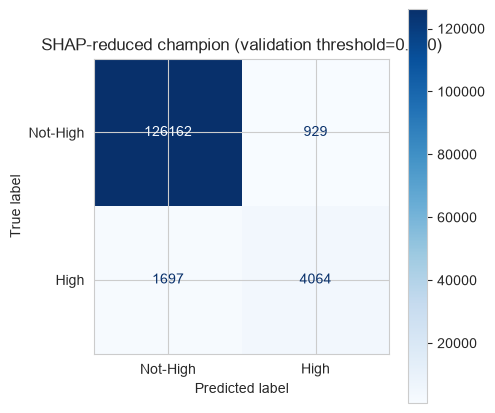


Test PR-AUC: 0.8301
Test ROC-AUC: 0.9752
Saved SHAP-refined model, selected features, threshold metadata, SHAP importance, and comparison.


In [34]:
# Final refit: only the previous champion, using the SHAP-selected feature subset.
X_train_selected = X_train.loc[:, SHAP_SELECTED_FEATURES]
X_test_selected = X_test.loc[:, SHAP_SELECTED_FEATURES]
SHAP_CHAMPION_MODEL = fit_champion_for_split(X_train_selected, y_train)
SHAP_TEST_PROBABILITY = SHAP_CHAMPION_MODEL.predict_proba(X_test_selected)[:, 1]
SHAP_TEST_PREDICTION = (SHAP_TEST_PROBABILITY >= DECISION_THRESHOLD).astype(int)

# Compare with the full-feature champion at the same validation-selected cutoff.
full_champion_probability = overall_champion.predict_proba(X_test)[:, 1]
full_champion_prediction = (full_champion_probability >= DECISION_THRESHOLD).astype(int)
full_champion_metrics = evaluate_predictions(
    y_test, full_champion_prediction, full_champion_probability,
    f"Previous full-feature champion ({overall_champion_name})",
)
shap_reduced_name = f"SHAP-reduced champion ({overall_champion_name})"
shap_reduced_result = evaluate_predictions(
    y_test, SHAP_TEST_PREDICTION, SHAP_TEST_PROBABILITY, shap_reduced_name
)
shap_refinement_comparison = pd.DataFrame([
    full_champion_metrics,
    shap_reduced_result,
]).set_index('strategy').round(4)
print("Held-out test comparison (threshold fixed using inner validation):")
display(shap_refinement_comparison)
print("SHAP-reduced champion classification report:")
print(classification_report(
    y_test, SHAP_TEST_PREDICTION,
    labels=TARGET_LABELS, target_names=TARGET_NAMES, zero_division=0,
))
cm_shap = confusion_matrix(y_test, SHAP_TEST_PREDICTION, labels=TARGET_LABELS)
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(cm_shap, display_labels=TARGET_NAMES).plot(ax=ax, colorbar=True, cmap='Blues')
ax.set_title(f'SHAP-reduced champion (validation threshold={DECISION_THRESHOLD:.3f})')
plt.tight_layout()
plt.show()
print(f"\nTest PR-AUC: {average_precision_score(y_test, SHAP_TEST_PROBABILITY):.4f}")
print(f"Test ROC-AUC: {roc_auc_score(y_test, SHAP_TEST_PROBABILITY):.4f}")

overall_champion = SHAP_CHAMPION_MODEL
overall_champion_name = shap_reduced_name
y_pred_final = SHAP_TEST_PREDICTION
shap_reduced_proba = SHAP_TEST_PROBABILITY
shap_final_importance = shap_importance
final_comparison = shap_refinement_comparison

import joblib
joblib.dump(SHAP_CHAMPION_MODEL, 'champion_model_v7_shap.pkl')
with open('feature_cols_v7_shap.json', 'w') as f:
    json.dump(SHAP_SELECTED_FEATURES, f, indent=2)
with open('label_thresholds_v7_shap.json', 'w') as f:
    json.dump({
        'high_threshold_ns': HIGH_THRESHOLD_NS,
        'decision_probability_threshold': DECISION_THRESHOLD,
        'threshold_selection': 'inner validation maximum High-class F1',
        'feature_selection': 'positive-class mean absolute SHAP; 95% cumulative importance',
        'previous_champion': PREVIOUS_CHAMPION_NAME,
        'imbalance_strategy': str(champion_strategy),
    }, f, indent=2)
shap_final_importance.to_csv('shap_feature_importance_v7.csv', header=['mean_abs_shap'])
shap_refinement_comparison.to_csv('shap_refinement_comparison_v7.csv')
print("Saved SHAP-refined model, selected features, threshold metadata, SHAP importance, and comparison.")

## Summary

- The preceding run has already selected the Random Forest champion; do not rerun all candidate models just to perform feature selection.
- **Section 10** clones that champion's estimator configuration and imbalance strategy, uses an inner training/validation split to compute positive-class SHAP importance, retains the smallest feature set covering 95% cumulative importance, chooses the threshold on validation, and retrains only the reduced-feature champion on all training data.
- The reduced model's final classification report, confusion matrix, PR-AUC, and ROC-AUC are computed on the held-out test split; the full-feature champion is compared at the same validation-selected threshold.
- If the earlier champion was selected using the same test split, treat test metrics as exploratory; use a genuinely untouched dataset/holdout for an unbiased final claim.

Run Section 10 after the previous run's champion and prepared train/test variables are available. The pipeline saves the model, exact feature list, threshold/selection metadata, and comparison outputs.

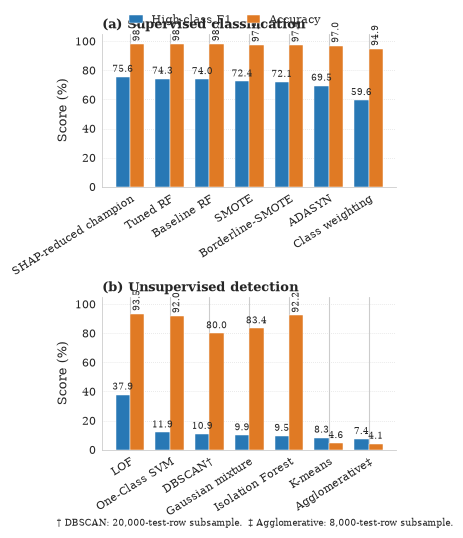

In [35]:
import matplotlib.pyplot as plt
import numpy as np

# Results from the supplied v7 supervised and v8 unsupervised comparison.
# Values are percentages. Only the two requested metrics are included.

supervised = {
    "Tuned RF":              {"f1": 74.30, "accuracy": 98.10},
    "Baseline RF":           {"f1": 74.00, "accuracy": 98.10},
    "SMOTE":                 {"f1": 72.40, "accuracy": 97.50},
    "Borderline-SMOTE":      {"f1": 72.10, "accuracy": 97.40},
    "ADASYN":                {"f1": 69.50, "accuracy": 97.00},
    "Class weighting":       {"f1": 59.60, "accuracy": 94.90},
}

supervised["SHAP-reduced champion"] = {
    "f1": 100 * shap_reduced_result["f1_high"],
    "accuracy": 100 * shap_reduced_result["accuracy"],
}

unsupervised = {
    "LOF":                   {"f1": 37.90, "accuracy": 93.45},
    "One-Class SVM":         {"f1": 11.88, "accuracy": 91.95},
    "DBSCAN†":               {"f1": 10.90, "accuracy": 80.00},
    "Gaussian mixture":      {"f1": 9.93,  "accuracy": 83.39},
    "Isolation Forest":      {"f1": 9.53,  "accuracy": 92.22},
    "K-means":               {"f1": 8.33,  "accuracy": 4.60},
    "Agglomerative‡":        {"f1": 7.37,  "accuracy": 4.13},
}

# Sort independently by High-class F1, highest first.
supervised = dict(sorted(supervised.items(),
                         key=lambda item: item[1]["f1"], reverse=True))
unsupervised = dict(sorted(unsupervised.items(),
                           key=lambda item: item[1]["f1"], reverse=True))

# Compact, readable settings for IEEE half-column width (~3.5 in).
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 8.5,
    "axes.labelsize": 9,
    "axes.titlesize": 9.5,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

F1_COLOR = "#2878B5"
ACC_COLOR = "#E07A24"

fig, axes = plt.subplots(
    nrows=2, ncols=1,
    figsize=(3.5, 5.4),
    sharey=True,
    constrained_layout=False
)

def add_panel(ax, results, title, panel_label):
    labels = list(results.keys())
    f1 = [results[name]["f1"] for name in labels]
    accuracy = [results[name]["accuracy"] for name in labels]

    x = np.arange(len(labels))
    width = 0.36

    bars_f1 = ax.bar(
        x - width / 2, f1, width,
        color=F1_COLOR, label="High-class F1",
        edgecolor="white", linewidth=0.35, zorder=3
    )
    bars_acc = ax.bar(
        x + width / 2, accuracy, width,
        color=ACC_COLOR, label="Accuracy",
        edgecolor="white", linewidth=0.35, zorder=3
    )

    ax.set_title(f"{panel_label} {title}", loc="left", pad=4, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=32, ha="right", rotation_mode="anchor")
    ax.set_ylim(0, 105)
    ax.set_yticks(np.arange(0, 101, 20))
    ax.set_ylabel("Score (%)")
    ax.grid(axis="y", linestyle=":", linewidth=0.55, alpha=0.65, zorder=0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(0.6)
    ax.spines["bottom"].set_linewidth(0.6)
    ax.tick_params(axis="both", length=2.5, width=0.6, pad=2)

    # Small numeric labels retain exact reported values without a separate table.
    for bars in (bars_f1, bars_acc):
        for bar in bars:
            h = bar.get_height()
            ax.annotate(
                f"{h:.1f}",
                (bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 2), textcoords="offset points",
                ha="center", va="bottom", fontsize=6.5,
                rotation=90 if h > 85 else 0,
                clip_on=False
            )

add_panel(axes[0], supervised, "Supervised classification", "(a)")
add_panel(axes[1], unsupervised, "Unsupervised detection", "(b)")

# One shared legend, avoiding duplicated legends in each panel.
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, legend_labels,
    loc="upper center", bbox_to_anchor=(0.5, 0.985),
    ncol=2, frameon=False, handlelength=1.2, columnspacing=1.4
)

fig.subplots_adjust(
    left=0.15, right=0.99, top=0.93, bottom=0.16,
    hspace=0.72
)

# Methodological note for the subsampled methods.
fig.text(
    0.02, 0.015,
    "† DBSCAN: 20,000-test-row subsample.  ‡ Agglomerative: 8,000-test-row subsample.",
    ha="left", va="bottom", fontsize=6.7
)

# Save a vector version for the paper and a high-resolution preview.
fig.savefig("bottleneck_twin_plot.pdf", bbox_inches="tight")
fig.savefig("bottleneck_twin_plot.png", dpi=600, bbox_inches="tight")
plt.show()


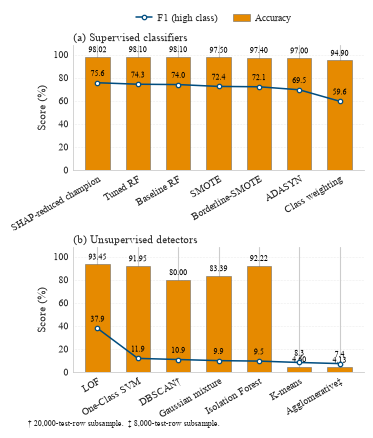

In [36]:
import matplotlib.pyplot as plt
import numpy as np

supervised = {
    "Tuned RF":         {"f1": 74.30, "accuracy": 98.10},
    "Baseline RF":      {"f1": 74.00, "accuracy": 98.10},
    "SMOTE":            {"f1": 72.40, "accuracy": 97.50},
    "Borderline-SMOTE": {"f1": 72.10, "accuracy": 97.40},
    "ADASYN":           {"f1": 69.50, "accuracy": 97.00},
    "Class weighting":  {"f1": 59.60, "accuracy": 94.90},
}
supervised["SHAP-reduced champion"] = {
    "f1": 100 * shap_reduced_result["f1_high"],
    "accuracy": 100 * shap_reduced_result["accuracy"],
}

unsupervised = {
    "LOF":              {"f1": 37.90, "accuracy": 93.45},
    "One-Class SVM":    {"f1": 11.88, "accuracy": 91.95},
    "DBSCAN†":          {"f1": 10.90, "accuracy": 80.00},
    "Gaussian mixture": {"f1": 9.93,  "accuracy": 83.39},
    "Isolation Forest": {"f1": 9.53,  "accuracy": 92.22},
    "K-means":          {"f1": 8.33,  "accuracy": 4.60},
    "Agglomerative‡":   {"f1": 7.37,  "accuracy": 4.13},
}

# Sort by F1 (descending)
supervised = dict(sorted(supervised.items(), key=lambda kv: kv[1]["f1"], reverse=True))
unsupervised = dict(sorted(unsupervised.items(), key=lambda kv: kv[1]["f1"], reverse=True))

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7.5,
    "axes.linewidth": 0.6,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

ACC_COLOR = "#E68A00"   # light gray bars (print/grayscale safe)
F1_COLOR = "#004D80"    # dark navy line
SHOW_F1_VALUES = True   # numeric labels on the F1 markers

fig, axes = plt.subplots(2, 1, figsize=(3.5, 4.3), sharey=True)
fig.subplots_adjust(left=0.15, right=0.98, top=0.90, bottom=0.14, hspace=0.62)


def draw_panel(ax, data, title):
    names = list(data.keys())
    f1 = np.array([data[n]["f1"] for n in names])
    acc = np.array([data[n]["accuracy"] for n in names])
    x = np.arange(len(names))

    bars = ax.bar(
        x, acc, width=0.6,
        color=ACC_COLOR,
        edgecolor="#6E6E6E",
        linewidth=0.4,
        label="Accuracy",
        zorder=2
    )
    ax.bar_label(
        bars,
        labels=[f"{v:.2f}" for v in acc],
        padding=2,
        fontsize=6,
        color= "#000000"
    )
    
    ax.plot(x, f1, color=F1_COLOR, marker="o", markersize=3.2, linewidth=1.1,
            markerfacecolor="white", markeredgewidth=0.9, label="F1 (high class)",
            zorder=3)

    if SHOW_F1_VALUES:
        for xi, v in zip(x, f1):
            ax.annotate(f"{v:.1f}", (xi, v), xytext=(0, 3.5),
                        textcoords="offset points", ha="center", va="bottom",
                        fontsize=6, color="#000000")

    ax.set_ylim(0, 108)
    ax.set_yticks(np.arange(0, 101, 20))
    ax.set_ylabel("Score (%)")
    ax.set_xticks(x)
    ax.set_xticklabels(names, rotation=30, ha="right", rotation_mode="anchor")
    ax.set_xlim(-0.6, len(names) - 0.4)
    ax.set_title(title, loc="left", pad=3, fontsize=8)

    ax.grid(axis="y", linestyle=":", linewidth=0.4, alpha=0.7, zorder=0)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="both", length=2, width=0.5, pad=1.5)


draw_panel(axes[0], supervised, "(a) Supervised classifiers")
draw_panel(axes[1], unsupervised, "(b) Unsupervised detectors")

# Single shared legend above both panels
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.55, 0.995),
           ncol=2, frameon=False, handlelength=1.6, columnspacing=1.5,
           handletextpad=0.5)

fig.text(0.02, 0.01,
         "† 20,000-test-row subsample.  ‡ 8,000-test-row subsample.",
         ha="left", va="bottom", fontsize=6)

fig.savefig("bottleneck_twin_plot.pdf", bbox_inches="tight")
fig.savefig("bottleneck_twin_plot.png", dpi=600, bbox_inches="tight")
plt.show()